In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# # extract_small_files_first.py
# import zipfile
# import os

# ZIP_PATH = "/content/drive/MyDrive/LSVH/LSVH.zip"
# OUTPUT = "LSVH_preview"

# os.makedirs(OUTPUT, exist_ok=True)

# files_to_extract = [
#     "LSVH/README.txt",
#     "LSVH/train.txt",
#     "LSVH/test.txt",
# ]

# with zipfile.ZipFile(ZIP_PATH) as z:
#     print("Available files in the beginning of the zip:")
#     for name in z.namelist()[:2]:
#         print("  ", name)

#     for name in z.namelist()[-5:]:
#         z.extract(name, OUTPUT)
#         print("  ", name)

#     print("\nExtracting only the small text files you want...")
#     for fname in files_to_extract:
#         if fname in z.namelist():
#             z.extract(fname, OUTPUT)
#             print(f"Extracted: {fname}")
#         else:
#             print(f"NOT FOUND: {fname}")


# print("\nDONE!")
# print(f"Open the folder → {os.path.abspath(OUTPUT)}")
# print("You can now safely open:")
# print("   README.txt")
# print("   train.txt  → contains image filenames for training")
# print("   test.txt   → contains image filenames for testing")

In [3]:
# ZIP_PATH = "/content/drive/MyDrive/LSVH/LSVH.zip"
# OUTPUT_DIR = "/content/drive/MyDrive/LSVH/ouput"

In [4]:
import json
import os
from sklearn.model_selection import train_test_split
from PIL import Image

# Paths
DATASET_DIR = "/kaggle/input/ahmad-lsvh/LSVH"
OUTPUT_DIR = "/kaggle/working"

os.makedirs(f"{OUTPUT_DIR}/annotations", exist_ok=True)

with open(os.path.join(DATASET_DIR, "train.txt")) as f:
    train_fns = [l.strip() for l in f if l.strip()]

with open(os.path.join(DATASET_DIR, "test.txt")) as f:
    test_fns = [l.strip() for l in f if l.strip()]

all_fns = train_fns + test_fns
print(f"Total images: {len(all_fns)}")

images = []
annotations = []
img_id = 1
ann_id = 1
kept = 0

for fname in all_fns:
    img_path = os.path.join(DATASET_DIR, "images", f"{fname}.jpg")
    lbl_path = os.path.join(DATASET_DIR, "labels", f"{fname}.txt")

    if not os.path.exists(img_path) or not os.path.exists(lbl_path):
        continue

    with Image.open(img_path) as img:
        w, h = img.size

    with open(lbl_path) as f:
        lines = f.read().strip().split("\n")

    valid = False

    for line in lines:
        if not line.strip():
            continue

        parts = line.split()
        obj_type = int(parts[0])  # 1=Car, 2=Bus, 3=Van, 4=Don't care

        if obj_type == 4:
            continue

        if obj_type not in [1, 2, 3]:
            continue

        x1, y1, x2, y2 = map(float, parts[4:8])

        if x2 <= x1 or y2 <= y1:
            continue

        annotations.append({
            "id": ann_id,
            "image_id": img_id,
            "category_id": 1,
            "bbox": [
                round(x1, 2),
                round(y1, 2),
                round(x2 - x1, 2),
                round(y2 - y1, 2)
            ],
            "area": round((x2 - x1) * (y2 - y1), 2),
            "iscrowd": 0
        })

        ann_id += 1
        valid = True

    if valid:
        images.append({
            "id": img_id,
            "file_name": img_path,
            "width": w,
            "height": h
        })
        img_id += 1
        kept += 1

print(f"Images kept after removing 'Don't care': {kept}")

train_imgs, val_imgs = train_test_split(
    images, test_size=0.2, random_state=42
)

def make_split(img_list):
    ids = {img["id"] for img in img_list}
    anns = [a for a in annotations if a["image_id"] in ids]
    return {
        "images": img_list,
        "annotations": anns,
        "categories": [{"id": 1, "name": "vehicle"}]
    }

with open(f"{OUTPUT_DIR}/annotations/train.json", "w") as f:
    json.dump(make_split(train_imgs), f, indent=2)

with open(f"{OUTPUT_DIR}/annotations/val.json", "w") as f:
    json.dump(make_split(val_imgs), f, indent=2)

print(f"Done! Train: {len(train_imgs)} | Val: {len(val_imgs)}")
print("Ready for Faster R-CNN (num_classes=2)")


Total images: 14388
Images kept after removing 'Don't care': 13938
Done! Train: 11150 | Val: 2788
Ready for Faster R-CNN (num_classes=2)


In [5]:
import gc; gc.collect()
print("Garbage Collected")

Garbage Collected


In [6]:
DATASET_DIR = "/kaggle/input/ahmad-lsvh/LSVH"
OUTPUT_DIR = "/kaggle/working"

In [7]:
import json
import torch
import numpy as np
from torch.utils.data import Dataset
from PIL import Image
import os

class LSVHDataset(Dataset):
    def __init__(self, json_path):
        with open(json_path, "r") as f:
            coco = json.load(f)

        self.images = coco["images"]
        self.annotations = coco["annotations"]

        self.ann_dict = {}
        for ann in self.annotations:
            self.ann_dict.setdefault(ann["image_id"], []).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_info = self.images[idx]
        file_path = img_info["file_name"]

        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Image not found: {file_path}")

        img = Image.open(file_path).convert("RGB")

        img_tensor = torch.from_numpy(
            np.array(img)
        ).permute(2, 0, 1).float() / 255.0

        anns = self.ann_dict.get(img_info["id"], [])

        if len(anns) > 0:
            boxes = []
            for ann in anns:
                x, y, w, h = ann["bbox"]
                boxes.append([x, y, x + w, y + h])

            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.ones((len(boxes),), dtype=torch.int64)
        else:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(img_info["id"])
        }

        return img_tensor, target, img


In [8]:
TRAIN_JSON_ANNOTATIONS = OUTPUT_DIR + "/annotations/train.json"
TEST_JSON_ANNOTATIONS = OUTPUT_DIR + "/annotations/val.json"

tensor([1, 1])
tensor([1])


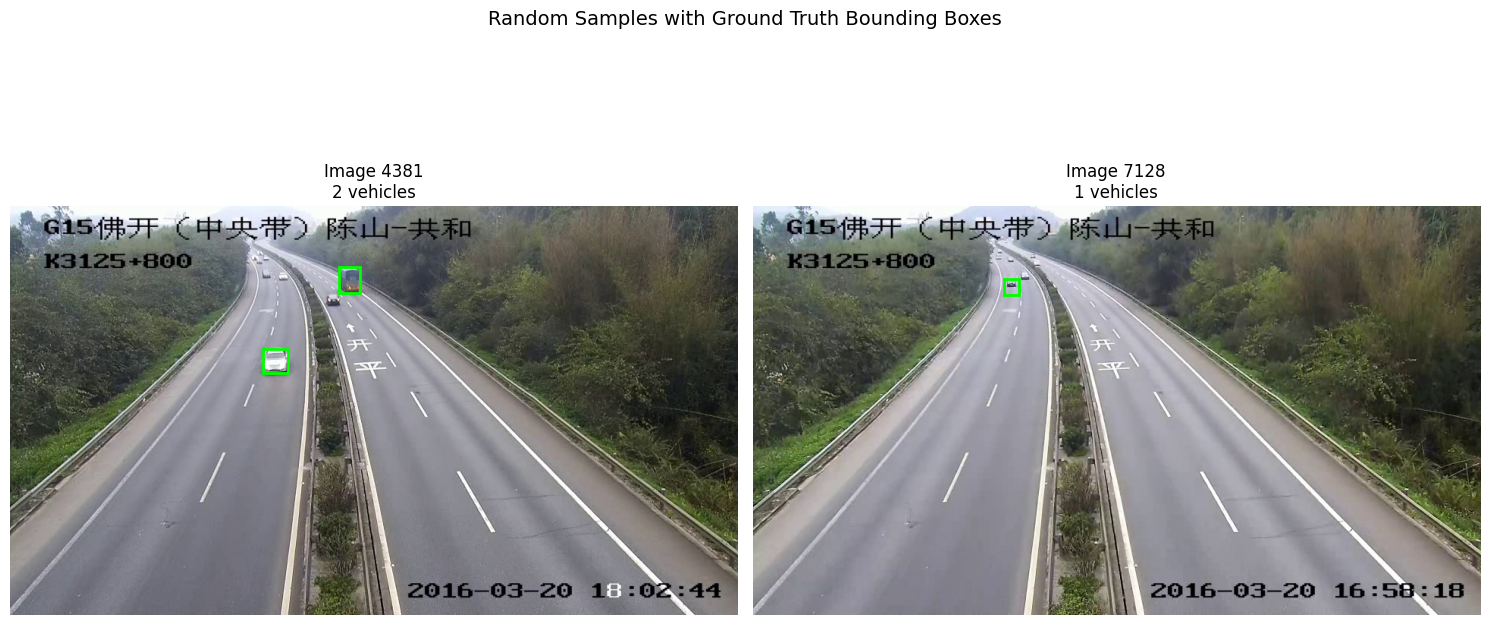

In [9]:
import torch
from torch.utils.data import Dataset
import zipfile
import json
import io
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
import numpy as np

def visualize_random_samples(zip_path="DATASET_DIR", json_path="LSVH_prepared/annotations/train.json", num_samples=2):
    dataset = LSVHDataset(json_path)

    plt.figure(figsize=(15, 8))
    indices = random.sample(range(len(dataset)), num_samples)

    for i, idx in enumerate(indices):
        img_tensor, target, pil_img = dataset[idx]
        boxes = target["boxes"].cpu().numpy()
        print(target['labels'])

        plt.subplot(1, num_samples, i+1)
        plt.imshow(pil_img)
        ax = plt.gca()

        for box in boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                   linewidth=2, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)

        plt.title(f"Image {idx}\n{len(boxes)} vehicles")
        plt.axis('off')

    plt.suptitle("Random Samples with Ground Truth Bounding Boxes", fontsize=14)
    plt.tight_layout()
    plt.show()
    del dataset
visualize_random_samples(zip_path=DATASET_DIR, json_path=TRAIN_JSON_ANNOTATIONS)

In [10]:
import torch.nn as nn
import torch.nn.functional as F
import torch
class SINetBoxHead(nn.Module):
    def __init__(self, in_channels=256, representation_size=1024):
        super().__init__()

        self.conv = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)

        self.fc6 = nn.Linear(in_channels * 7 * 7, representation_size)
        self.fc7 = nn.Linear(representation_size, representation_size)

    def forward(self, x):
        # x: [N, 256, 7, 7]
        x = F.relu(self.conv(x))
        x = x.flatten(start_dim=1)
        x = F.relu(self.fc6(x))
        x = F.relu(self.fc7(x))
        return x

In [11]:

def soft_nms(boxes, scores, iou_threshold=0.5, sigma=0.5, score_threshold=0.001):
    keep = []
    idxs = scores.argsort(descending=True)

    while idxs.numel() > 0:
        i = idxs[0]
        keep.append(i)

        if idxs.numel() == 1:
            break

        cur_box = boxes[i].unsqueeze(0)
        other_boxes = boxes[idxs[1:]]

        ious = torchvision.ops.box_iou(cur_box, other_boxes).squeeze(0)

        decay = torch.exp(-(ious ** 2) / sigma)
        scores[idxs[1:]] *= decay

        idxs = idxs[1:][scores[idxs[1:]] > score_threshold]

    return torch.tensor(keep, device=boxes.device)
    
import torchvision
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.roi_heads import RoIHeads

class SoftNMSRoIHeads(RoIHeads):
    def postprocess_detections(self, class_logits, box_regression, proposals, image_shapes):
        boxes, scores, labels = super().postprocess_detections(
            class_logits, box_regression, proposals, image_shapes
        )

        final_boxes = []
        final_scores = []
        final_labels = []

        for b, s, l in zip(boxes, scores, labels):
            keep = soft_nms(b, s)
            final_boxes.append(b[keep])
            final_scores.append(s[keep])
            final_labels.append(l[keep])

        return final_boxes, final_scores, final_labels


In [12]:
from torchvision.models.detection.backbone_utils import mobilenet_backbone
from torchvision.ops import MultiScaleRoIAlign
from torchvision.models.detection.rpn import AnchorGenerator

def create_sinet_model(num_classes=2):
    backbone = mobilenet_backbone(
        "mobilenet_v2",
        pretrained=True,
        fpn=True,
        trainable_layers=2
    )

    anchor_generator = AnchorGenerator(
        sizes=((32,), (64,), (128,)),
        aspect_ratios=((0.5, 1.0, 2.0),) * 3
    )

    roi_pooler = MultiScaleRoIAlign(
        featmap_names=['0', '1', '2', '3'],
        output_size=7,
        sampling_ratio=2
    )

    box_head = SINetBoxHead(256, 1024)

    model = FasterRCNN(
        backbone=backbone,
        num_classes=num_classes,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        box_head=box_head
    )

    model.roi_heads.__class__ = SoftNMSRoIHeads

    return model


In [13]:
model = create_sinet_model(2)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'backbone_name' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/m

Total parameters: 18,829,017
Trainable parameters: 18,302,617


In [14]:
# !pip install torchmetrics

In [15]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision
def evaluate_map50(model, dataloader, device="cuda"):
    metric = MeanAveragePrecision(iou_thresholds=[0.5])
    model.eval()

    with torch.no_grad():
        for images, targets, _ in dataloader:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            outputs = model(images)

            outputs = [{k: v.cpu() for k, v in o.items()} for o in outputs]
            targets = [{k: v.cpu() for k, v in t.items()} for t in targets]

            metric.update(outputs, targets)

    results = metric.compute()
    return results["map_50"].item() * 100


In [16]:
import os

CHECKPOINT_DIR = "checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def save_checkpoint(epoch, model, optimizer, best_map50, filename):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_map50": best_map50
    }, filename)
def load_checkpoint(filename, model, optimizer, device):
    checkpoint = torch.load(filename, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_map50 = checkpoint["best_map50"]
    print(f"Resumed from epoch {start_epoch}")
    return start_epoch, best_map50


In [17]:
import random
import torch
from torch.utils.data import DataLoader, Subset, ConcatDataset

random.seed(41)
torch.manual_seed(41)

train_dataset_full = LSVHDataset(TRAIN_JSON_ANNOTATIONS)
val_dataset_full   = LSVHDataset(TEST_JSON_ANNOTATIONS)
test_dataset = val_dataset_full

num_train = len(train_dataset_full)
train_indices = list(range(num_train))
random.shuffle(train_indices)

train_40_idx = train_indices[:int(0.40 * num_train)]
val_10_idx   = train_indices[int(0.40 * num_train):int(0.50 * num_train)]

train_40_dataset = Subset(train_dataset_full, train_40_idx)
val_10_dataset   = Subset(train_dataset_full, val_10_idx)

num_val = len(val_dataset_full)
val_indices = list(range(num_val))
random.shuffle(val_indices)

val_20_idx = val_indices[:int(0.20 * num_val)]
val_20_dataset = Subset(val_dataset_full, val_20_idx)

final_train_dataset = ConcatDataset([
    train_40_dataset,
    val_20_dataset
])

BATCH_SIZE = 8
batch_size = BATCH_SIZE

train_loader = DataLoader(
    final_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=True,
    collate_fn=lambda x: tuple(zip(*x)),
    num_workers=4
)

val_loader = DataLoader(
    val_10_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=lambda x: tuple(zip(*x)),
    num_workers=4
)
print("Dataloaders maked")

Dataloaders maked


In [18]:
import gc; gc.collect()

0

In [19]:
from torch.utils.data import DataLoader

model = create_sinet_model(num_classes=2)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
model.to(device)
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(
    params,
    lr=1e-4
)
num_epochs = 50
model.train()
train_losses = []
val_losses = []
val_map50 = []
train_map50 = []

best_loss = np.inf
print("Start Training")
for epoch in range(50):
    print("In epoch " ,epoch)
    model.train()
    epoch_loss = 0.0
    for images, targets , _ in train_loader:
        images = [img.to(device, non_blocking=True) for img in images]
        targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]
    

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        epoch_loss += losses.item()
    print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss:.4f}")
    train_losses.append(epoch_loss)
    val_loss = 0.0
    with torch.no_grad():
        for images, targets, _ in val_loader:
            images = [img.to(device, non_blocking=True) for img in images]
            targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]
    
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            val_loss += losses.item()
    val_losses.append(val_loss)

    print(f"Epoch Val Loss [{epoch+1}/{num_epochs}] - Loss: {val_loss:.4f}")
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        save_checkpoint(
            epoch,
            model,
            optimizer,
            best_loss,
            f"{CHECKPOINT_DIR}/best_model.pth"
        )
        print("Best model saved")

    save_checkpoint(
        epoch,
        model,
        optimizer,
        epoch_loss,
        f"{CHECKPOINT_DIR}/last_checkpoint.pth"
    )

    if (epoch + 1) % 10 == 0:
      map50 = evaluate_map50(model, val_loader)
      map50_train = evaluate_map50(model, val_loader)
      print(f"Validation mAP@50 at epoch {epoch+1}: {map50:.2f}%")
      print(f"Train mAP@50 at epoch {epoch+1}: {map50_train:.2f}%")
      train_map50.append(map50_train)
      val_map50.append(map50)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'backbone_name' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


cuda
Start Training
In epoch  0
Epoch [1/50] - Loss: 147.8247
Epoch Val Loss [1/50] - Loss: 30.6830
Best model saved
In epoch  1
Epoch [2/50] - Loss: 113.9534
Epoch Val Loss [2/50] - Loss: 25.4707
Best model saved
In epoch  2
Epoch [3/50] - Loss: 102.2902
Epoch Val Loss [3/50] - Loss: 22.4844
Best model saved
In epoch  3
Epoch [4/50] - Loss: 94.7174
Epoch Val Loss [4/50] - Loss: 22.8252
Best model saved
In epoch  4
Epoch [5/50] - Loss: 90.5445
Epoch Val Loss [5/50] - Loss: 22.4422
Best model saved
In epoch  5
Epoch [6/50] - Loss: 85.4473
Epoch Val Loss [6/50] - Loss: 21.5297
Best model saved
In epoch  6
Epoch [7/50] - Loss: 82.2107
Epoch Val Loss [7/50] - Loss: 21.3777
Best model saved
In epoch  7
Epoch [8/50] - Loss: 78.4568
Epoch Val Loss [8/50] - Loss: 19.8807
Best model saved
In epoch  8
Epoch [9/50] - Loss: 76.0982
Epoch Val Loss [9/50] - Loss: 20.5047
Best model saved
In epoch  9
Epoch [10/50] - Loss: 72.8801
Epoch Val Loss [10/50] - Loss: 20.2645
Best model saved
Validation mAP@

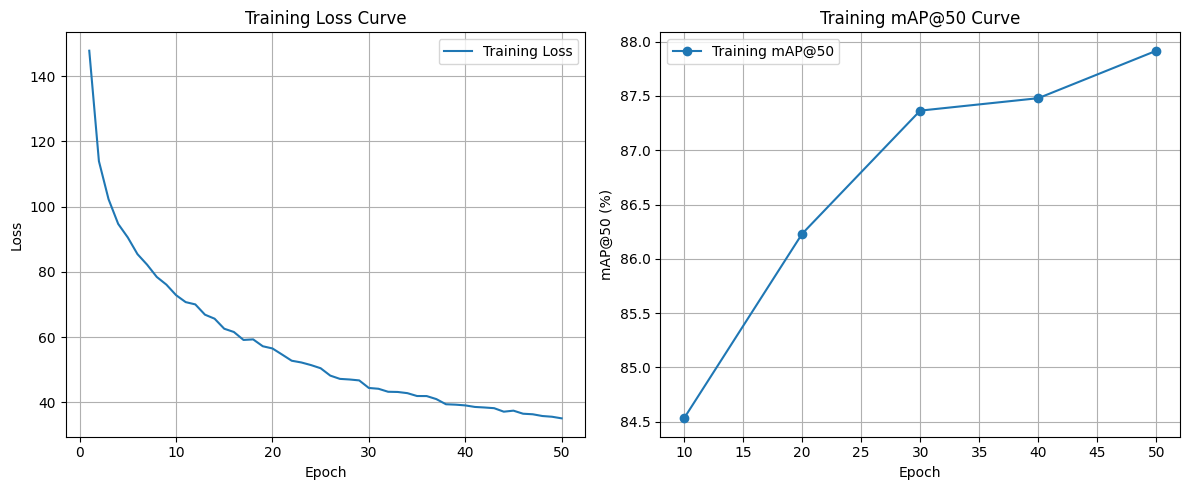

In [20]:
def plot_training_curves(train_losses, val_map50, title):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label=title + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title +" Loss Curve")
    plt.grid()
    plt.legend()

    plt.subplot(1, 2, 2)
    map_epochs = range(10, 10 * len(val_map50) + 1, 10)
    plt.plot(map_epochs, val_map50, marker="o", label=title+ " mAP@50")
    plt.xlabel("Epoch")
    plt.ylabel("mAP@50 (%)")
    plt.title(title +  " mAP@50 Curve")
    plt.grid()
    plt.legend()

    plt.tight_layout()
    plt.show()
plot_training_curves(train_losses, train_map50, "Training")


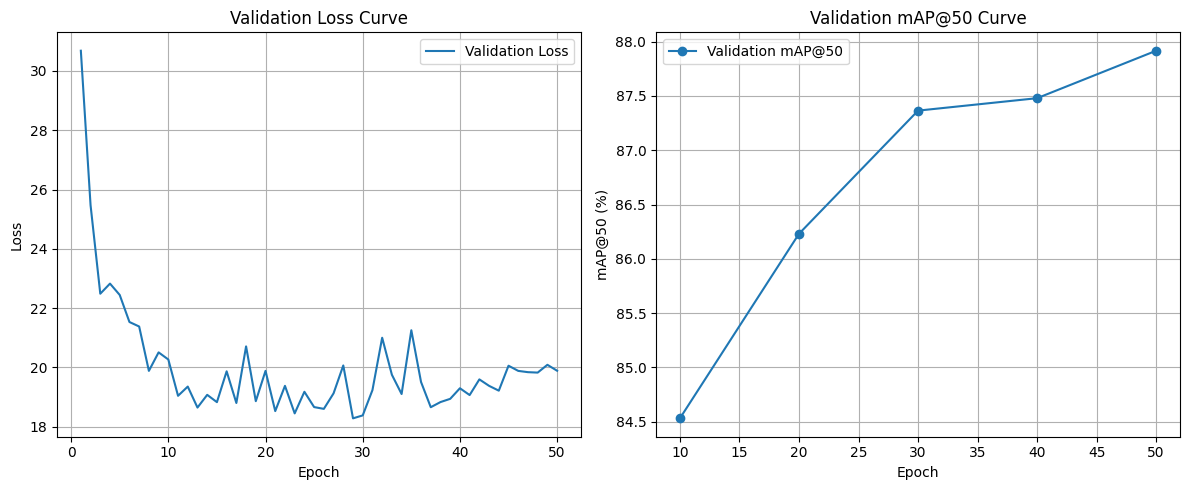

In [21]:
plot_training_curves(val_losses, val_map50, "Validation")

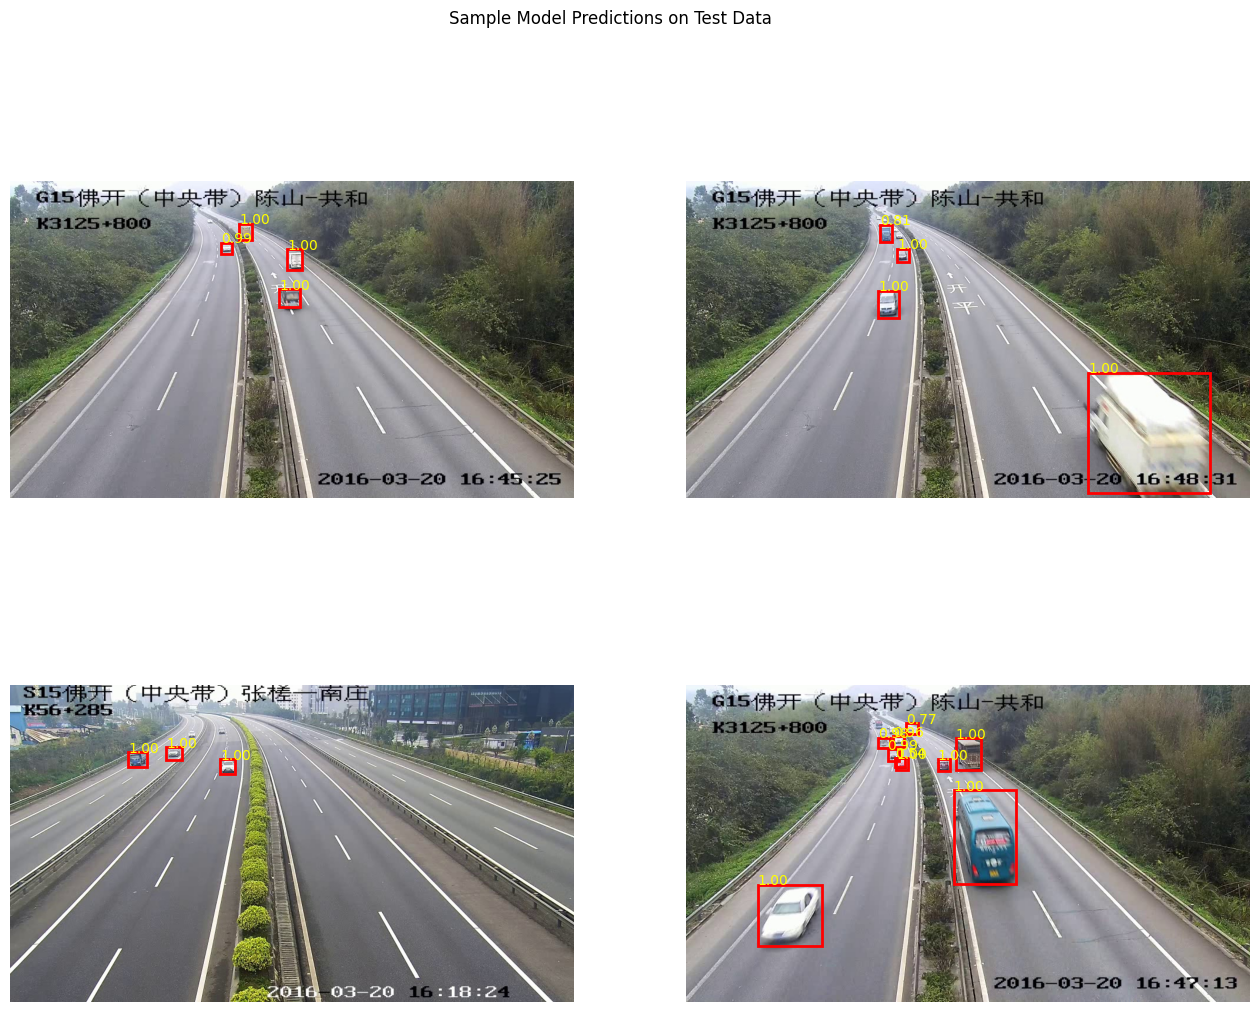

In [22]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as FF
from torchvision.ops import box_convert
import random
def visualize_predictions(model, test_dataset, device="cuda", num_samples=4):
    model.eval()
    indices = random.sample(range(len(test_dataset)), num_samples)

    plt.figure(figsize=(16, 12))

    with torch.no_grad():
        for i, idx in enumerate(indices):
            image, _, _ = test_dataset[idx]
            img_tensor = image.to(device)

            output = model([img_tensor])[0]

            img = FF.to_pil_image(image)

            plt.subplot(2, 2, i + 1)
            plt.imshow(img)
            plt.axis("off")

            for box, score in zip(output["boxes"], output["scores"]):
                if score < 0.5:
                    continue
                x1, y1, x2, y2 = box.cpu().numpy()
                plt.gca().add_patch(
                    plt.Rectangle(
                        (x1, y1),
                        x2 - x1,
                        y2 - y1,
                        fill=False,
                        edgecolor="red",
                        linewidth=2
                    )
                )
                plt.text(x1, y1, f"{score:.2f}", color="yellow")

    plt.suptitle("Sample Model Predictions on Test Data")
    plt.show()
visualize_predictions(model, test_dataset, device)

In [23]:
test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=lambda x: tuple(zip(*x)),
    num_workers=4
)
test_map50 = evaluate_map50(model, test_loader, device)
print(f"✅ Final Test mAP@50: {test_map50:.2f}%")

✅ Final Test mAP@50: 87.96%
